In [2]:

import sys
from pathlib import Path

# Make the project root accessible
project_root = Path.cwd().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.quantum_grover.oracle import (
    create_grover_oracle,
    find_marked_inputs
)
from src.hash_functions.toy_hash import create_toy_hash_system

# Fixed search-space configuration
n_bits = 3
m_bits = 3
N = 2 ** n_bits

print(f"Input bits: {n_bits}")
print(f"Total possible inputs: {N}")

# IMPORTANT: This function returns only hash_map
hash_map = create_toy_hash_system(
    n_bits=n_bits,
    m_bits=m_bits
)

# Group inputs by their hash output
hash_counts = {}

for input_value, hash_value in hash_map.items():
    hash_counts.setdefault(hash_value, []).append(input_value)

print("\nAvailable target hashes and matching inputs:")
print("-" * 50)

for target_hash, matches in hash_counts.items():
    print(
        f"Target hash: {target_hash:03b} "
        f"| Matching inputs: {matches} "
        f"| M = {len(matches)}"
    )


Input bits: 3
Total possible inputs: 8

--- Toy Hash System Configuration ---
Input Bit Size (n): 3 (Total inputs: 8)
Hash Output Size (m): 3 bits
-------------------------------------------------------
Input (Binary)   | Input (Dec)  | Hash Output (Binary)
-------------------------------------------------------
|000>           | 0            | |000>
|001>           | 1            | |001>
|010>           | 2            | |010>
|011>           | 3            | |011>
|100>           | 4            | |100>
|101>           | 5            | |111>
|110>           | 6            | |110>
|111>           | 7            | |101>
-------------------------------------------------------

Available target hashes and matching inputs:
--------------------------------------------------
Target hash: 000 | Matching inputs: [0] | M = 1
Target hash: 001 | Matching inputs: [1] | M = 1
Target hash: 010 | Matching inputs: [2] | M = 1
Target hash: 011 | Matching inputs: [3] | M = 1
Target hash: 100 | Matching i

In [3]:

# Experiment configuration
n_bits = 3
N = 2 ** n_bits

# Create a test hash map with configurable matching inputs
M = int(input(f"How many matching inputs (1-{N})? "))

if not 1 <= M <= N:
    raise ValueError(f"M must be between 1 and {N}.")

target_hash = "MATCH"

hash_map = {
    input_value: (
        target_hash if input_value < M
        else f"OTHER_{input_value}"
    )
    for input_value in range(N)
}

# Use our existing oracle functions
marked_inputs = find_marked_inputs(hash_map, target_hash)

oracle = create_grover_oracle(
    hash_map,
    target_hash,
    n_bits
)

print(f"\nTotal inputs: {N}")
print(f"Requested matching inputs: {M}")
print(f"Oracle-marked inputs: {marked_inputs}")
print(f"Actual number marked: {len(marked_inputs)}")
print(f"Oracle qubits: {oracle.num_qubits}")

assert len(marked_inputs) == M
print("\nSUCCESS: The oracle marks exactly M inputs!")



Total inputs: 8
Requested matching inputs: 2
Oracle-marked inputs: [0, 1]
Actual number marked: 2
Oracle qubits: 3

SUCCESS: The oracle marks exactly M inputs!


In [4]:
import inspect

print(inspect.signature(
    __import__(
        "src.quantum_grover.grover_search",
        fromlist=["create_grover_circuit"]
    ).create_grover_circuit
))

(hash_map: dict, target_hash, n_bits: int, iterations: int | None = None) -> qiskit.circuit.quantumcircuit.QuantumCircuit


In [5]:

import math
from qiskit.quantum_info import Statevector

from src.quantum_grover.grover_search import create_grover_circuit

# Calculate the theoretical optimal iteration count
N = 2 ** n_bits
theta = math.asin(math.sqrt(M / N))

optimal_iterations = max(
    0,
    round(math.pi / (4 * theta) - 0.5)
)

print(f"Total inputs: {N}")
print(f"Matching inputs: {M}")
print(f"Grover iterations: {optimal_iterations}")

# Create the circuit using your existing implementation
grover_circuit = create_grover_circuit(
    hash_map=hash_map,
    target_hash=target_hash,
    n_bits=n_bits,
    iterations=optimal_iterations
)

# Remove final measurements if present, to calculate exact probabilities
probability_circuit = grover_circuit.remove_final_measurements(inplace=False)

statevector = Statevector.from_instruction(probability_circuit)
probabilities = statevector.probabilities()

# Sum the probabilities of all matching inputs
marked_inputs = [
    value for value, hash_value in hash_map.items()
    if hash_value == target_hash
]

success_probability = sum(
    probabilities[value] for value in marked_inputs
)

theoretical_probability = math.sin(
    (2 * optimal_iterations + 1) * theta
) ** 2

print(f"\nMarked inputs: {marked_inputs}")
print(f"Theoretical success probability: {theoretical_probability * 100:.2f}%")
print(f"Qiskit statevector success probability: {success_probability * 100:.2f}%")

assert math.isclose(
    success_probability,
    theoretical_probability,
    abs_tol=1e-8
), "The theoretical and Qiskit probabilities do not match!"

print("\nSUCCESS: Qiskit matches the theoretical probability!")


Total inputs: 8
Matching inputs: 2
Grover iterations: 1

Marked inputs: [0, 1]
Theoretical success probability: 100.00%
Qiskit statevector success probability: 100.00%

SUCCESS: Qiskit matches the theoretical probability!


In [7]:

import math
import pandas as pd
from qiskit.quantum_info import Statevector
from src.quantum_grover.grover_search import create_grover_circuit

# Fixed search space
n_bits = 3
N = 2 ** n_bits

experiment_results = []

for M in range(1, N + 1):

    # Create a controlled test hash map with exactly M matches
    target_hash = "MATCH"

    test_hash_map = {
        value: (
            target_hash if value < M
            else f"OTHER_{value}"
        )
        for value in range(N)
    }

    # Calculate the iteration count
    theta = math.asin(math.sqrt(M / N))

    if M == N:
        iterations = 0
    else:
        iterations = max(
            0,
            round(math.pi / (4 * theta) - 0.5)
        )

    # Build the existing Grover circuit
    circuit = create_grover_circuit(
        hash_map=test_hash_map,
        target_hash=target_hash,
        n_bits=n_bits,
        iterations=iterations
    )

    # Calculate exact statevector probabilities
    circuit_without_measurements = (
        circuit.remove_final_measurements(inplace=False)
    )

    statevector = Statevector.from_instruction(
        circuit_without_measurements
    )

    probabilities = statevector.probabilities()

    # Sum the probabilities of all marked inputs
    marked_inputs = list(range(M))

    qiskit_probability = sum(
        probabilities[value] for value in marked_inputs
    )

    theoretical_probability = math.sin(
        (2 * iterations + 1) * theta
    ) ** 2

    # Verify the result for each experiment
    assert math.isclose(
        qiskit_probability,
        theoretical_probability,
        abs_tol=1e-8
    ), f"Probability mismatch for M={M}"

    experiment_results.append({
        "Input Bits": n_bits,
        "Total Inputs (N)": N,
        "Matching Inputs (M)": M,
        "Grover Iterations": iterations,
        "Theoretical Success (%)": round(
            theoretical_probability * 100, 4
        ),
        "Qiskit Success (%)": round(
            qiskit_probability * 100, 4
        ),
        "Verified": "PASS"
    })

matching_experiment_df = pd.DataFrame(experiment_results)

display(matching_experiment_df)

print("\nSUCCESS: All matching-input experiments passed!")


,Input Bits,Total Inputs (N),Matching Inputs (M),Grover Iterations,Theoretical Success (%),Qiskit Success (%),Verified
0,3,8,1,2,94.5312,94.5312,PASS
1,3,8,2,1,100.0000,100.0000,PASS
2,3,8,3,1,84.3750,84.3750,PASS
3,3,8,4,0,50.0000,50.0000,PASS
4,3,8,5,0,62.5000,62.5000,PASS
5,3,8,6,0,75.0000,75.0000,PASS
6,3,8,7,0,87.5000,87.5000,PASS
7,3,8,8,0,100.0000,100.0000,PASS



SUCCESS: All matching-input experiments passed!


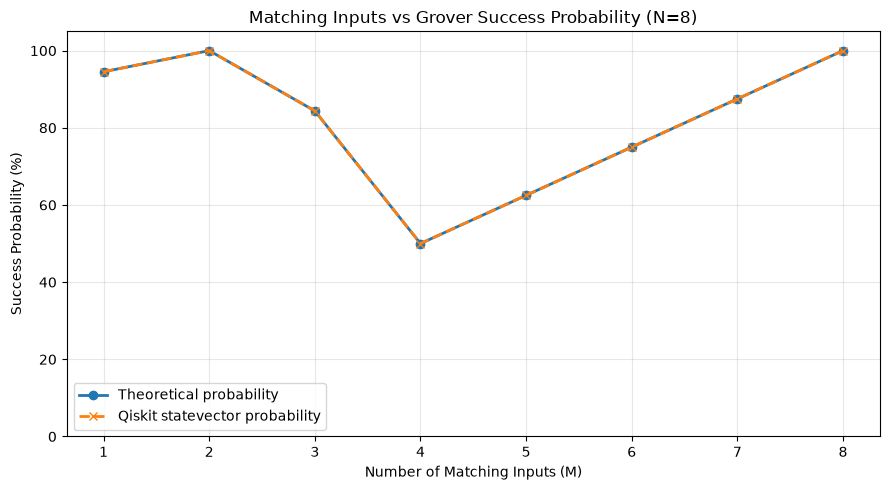

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    matching_experiment_df["Matching Inputs (M)"],
    matching_experiment_df["Theoretical Success (%)"],
    marker="o",
    linewidth=2,
    label="Theoretical probability"
)

plt.plot(
    matching_experiment_df["Matching Inputs (M)"],
    matching_experiment_df["Qiskit Success (%)"],
    marker="x",
    linestyle="--",
    linewidth=2,
    label="Qiskit statevector probability"
)

plt.xlabel("Number of Matching Inputs (M)")
plt.ylabel("Success Probability (%)")

plt.title(
    f"Matching Inputs vs Grover Success Probability (N={N})"
)

plt.xticks(range(1, N + 1))
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [9]:

from pathlib import Path

# Create the results directory if it doesn't exist
results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save all eight matching-input experiments
csv_path = results_dir / "grover_matching_inputs.csv"

matching_experiment_df.to_csv(csv_path, index=False)

print("Experiment results saved successfully!")
print(f"File location: {csv_path.resolve()}")
print(f"Experiments saved: {len(matching_experiment_df)}")


Experiment results saved successfully!
File location: D:\quantum-project\results\grover_matching_inputs.csv
Experiments saved: 8


In [11]:

import pandas as pd
import math
from pathlib import Path

csv_path = Path("../results/grover_matching_inputs.csv")

saved_results = pd.read_csv(csv_path)

print("Number of saved experiments:", len(saved_results))
print("Matching-input counts:",
      saved_results["Matching Inputs (M)"].tolist())

assert len(saved_results) == 8
assert saved_results["Matching Inputs (M)"].tolist() == list(range(1, 9))

assert all(
    math.isclose(theory, qiskit, abs_tol=1e-4)
    for theory, qiskit in zip(
        saved_results["Theoretical Success (%)"],
        saved_results["Qiskit Success (%)"]
    )
)

print("\nSUCCESS: CSV validation passed!")
display(saved_results)


Number of saved experiments: 8
Matching-input counts: [1, 2, 3, 4, 5, 6, 7, 8]

SUCCESS: CSV validation passed!


,Input Bits,Total Inputs (N),Matching Inputs (M),Grover Iterations,Theoretical Success (%),Qiskit Success (%),Verified
0,3,8,1,2,94.5312,94.5312,PASS
1,3,8,2,1,100.0000,100.0000,PASS
2,3,8,3,1,84.3750,84.3750,PASS
3,3,8,4,0,50.0000,50.0000,PASS
4,3,8,5,0,62.5000,62.5000,PASS
5,3,8,6,0,75.0000,75.0000,PASS
6,3,8,7,0,87.5000,87.5000,PASS
7,3,8,8,0,100.0000,100.0000,PASS


In [12]:

import importlib

modules_to_check = [
    "src.hash_functions.toy_hash",
    "src.classical_attack.preimage_search",
    "src.quantum_grover.oracle",
    "src.quantum_grover.grover_search",
]

print("CORE MODULE VALIDATION")
print("-" * 45)

for module_name in modules_to_check:
    try:
        importlib.import_module(module_name)
        print(f"PASS: {module_name}")
    except Exception as error:
        print(f"FAIL: {module_name}")
        print(f"Error: {error}")

print("\nModule validation finished.")


CORE MODULE VALIDATION
---------------------------------------------
PASS: src.hash_functions.toy_hash
PASS: src.classical_attack.preimage_search
PASS: src.quantum_grover.oracle
PASS: src.quantum_grover.grover_search

Module validation finished.
